## Import Libraries
python

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [4]:
df= pd.read_csv("auto_imports.csv")
df

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [5]:
df.head()

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250


In [6]:
print(df.shape)

(200, 26)


In [7]:
df.head()

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250


In [8]:
print(df.isnull().sum())


3              0
?              0
alfa-romero    0
gas            0
std            0
two            0
convertible    0
rwd            0
front          0
88.60          0
168.80         0
64.10          0
48.80          0
2548           0
dohc           0
four           0
130            0
mpfi           0
3.47           0
2.68           0
9.00           0
111            0
5000           0
21             0
27             0
13495          0
dtype: int64


In [10]:
# Step: Fill Missing Values

# 1. normalized_losses → numeric column with many missing values.
#    We'll fill with the mean because it's continuous data.
#df["normalized_losses"] = df["normalized_losses"].fillna(df["normalized_losses"].mean())

# 2. bore, stroke → numeric engine measurements.
#    Fill with mean to preserve realistic values.
#df["bore"] = df["bore"].fillna(df["bore"].mean())
#df["stroke"] = df["stroke"].fillna(df["stroke"].mean())

# 3. horsepower, peak_rpm → numeric performance features.
#    Fill with mean so the model can still use them.
#df["horsepower"] = df["horsepower"].fillna(df["horsepower"].mean())
#df["peak_rpm"] = df["peak_rpm"].fillna(df["peak_rpm"].mean())

# 4. num_doors → categorical column.
#    Fill with mode (most frequent value) because categories don’t have averages.
#df["num_doors"] = df["num_doors"].fillna(df["num_doors"].mode()[0])


In [11]:
print(df.isnull().sum())

3              0
?              0
alfa-romero    0
gas            0
std            0
two            0
convertible    0
rwd            0
front          0
88.60          0
168.80         0
64.10          0
48.80          0
2548           0
dohc           0
four           0
130            0
mpfi           0
3.47           0
2.68           0
9.00           0
111            0
5000           0
21             0
27             0
13495          0
dtype: int64


In [12]:
columns = ["symboling","normalized_losses","make","fuel_type","aspiration","num_doors",
           "body_style","drive_wheels","engine_location","wheel_base","length","width","height",
           "curb_weight","engine_type","num_cylinders","engine_size","fuel_system","bore","stroke",
           "compression_ratio","horsepower","peak_rpm","city_mpg","highway_mpg","price"]

df.columns = columns


In [13]:
df

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [14]:
#Replace '?'with NaN
df.replace("?",np.nan,inplace=True)

In [15]:
df = df.dropna(subset=["price"])


In [16]:
df

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,NaN,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [17]:
numeric_cols = ["normalized_losses","wheel_base","length","width","height","curb_weight",
                "engine_size","bore","stroke","compression_ratio","horsepower","peak_rpm",
                "city_mpg","highway_mpg","price"]

In [18]:
df[numeric_cols] = df[numeric_cols].astype(float)

In [19]:
df

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130.0,mpfi,3.47,2.68,9.0,111.0,5000.0,21.0,27.0,16500.0
1,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152.0,mpfi,2.68,3.47,9.0,154.0,5000.0,19.0,26.0,16500.0
2,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109.0,mpfi,3.19,3.40,10.0,102.0,5500.0,24.0,30.0,13950.0
3,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136.0,mpfi,3.19,3.40,8.0,115.0,5500.0,18.0,22.0,17450.0
4,2,NaN,audi,gas,std,two,sedan,fwd,front,99.8,...,136.0,mpfi,3.19,3.40,8.5,110.0,5500.0,19.0,25.0,15250.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141.0,mpfi,3.78,3.15,9.5,114.0,5400.0,23.0,28.0,16845.0
196,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141.0,mpfi,3.78,3.15,8.7,160.0,5300.0,19.0,25.0,19045.0
197,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173.0,mpfi,3.58,2.87,8.8,134.0,5500.0,18.0,23.0,21485.0
198,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145.0,idi,3.01,3.40,23.0,106.0,4800.0,26.0,27.0,22470.0


In [20]:
categorical_cols = ["make","fuel_type","aspiration","num_doors","body_style",
                    "drive_wheels","engine_location","engine_type","num_cylinders","fuel_system"]

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

In [21]:
df

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,0,1,0,2,0,2,0,88.6,...,130.0,5,3.47,2.68,9.0,111.0,5000.0,21.0,27.0,16500.0
1,1,NaN,0,1,0,2,2,2,0,94.5,...,152.0,5,2.68,3.47,9.0,154.0,5000.0,19.0,26.0,16500.0
2,2,164.0,1,1,0,0,3,1,0,99.8,...,109.0,5,3.19,3.40,10.0,102.0,5500.0,24.0,30.0,13950.0
3,2,164.0,1,1,0,0,3,0,0,99.4,...,136.0,5,3.19,3.40,8.0,115.0,5500.0,18.0,22.0,17450.0
4,2,NaN,1,1,0,2,3,1,0,99.8,...,136.0,5,3.19,3.40,8.5,110.0,5500.0,19.0,25.0,15250.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95.0,21,1,0,0,3,2,0,109.1,...,141.0,5,3.78,3.15,9.5,114.0,5400.0,23.0,28.0,16845.0
196,-1,95.0,21,1,1,0,3,2,0,109.1,...,141.0,5,3.78,3.15,8.7,160.0,5300.0,19.0,25.0,19045.0
197,-1,95.0,21,1,0,0,3,2,0,109.1,...,173.0,5,3.58,2.87,8.8,134.0,5500.0,18.0,23.0,21485.0
198,-1,95.0,21,0,1,0,3,2,0,109.1,...,145.0,3,3.01,3.40,23.0,106.0,4800.0,26.0,27.0,22470.0


In [23]:
print(df.head())

   symboling  normalized_losses  make  fuel_type  aspiration  num_doors  \
0          3                NaN     0          1           0          2   
1          1                NaN     0          1           0          2   
2          2              164.0     1          1           0          0   
3          2              164.0     1          1           0          0   
4          2                NaN     1          1           0          2   

   body_style  drive_wheels  engine_location  wheel_base  ...  engine_size  \
0           0             2                0        88.6  ...        130.0   
1           2             2                0        94.5  ...        152.0   
2           3             1                0        99.8  ...        109.0   
3           3             0                0        99.4  ...        136.0   
4           3             1                0        99.8  ...        136.0   

   fuel_system  bore  stroke  compression_ratio  horsepower  peak_rpm  \
0      

In [24]:
df.fillna(method="ffill", inplace=True)

C:\Users\kalya\AppData\Local\Temp\ipykernel_32468\173857299.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method="ffill", inplace=True)


In [25]:
df.info

<bound method DataFrame.info of      symboling  normalized_losses  make  fuel_type  aspiration  num_doors  \
0            3                NaN     0          1           0          2   
1            1                NaN     0          1           0          2   
2            2              164.0     1          1           0          0   
3            2              164.0     1          1           0          0   
4            2              164.0     1          1           0          2   
..         ...                ...   ...        ...         ...        ...   
195         -1               95.0    21          1           0          0   
196         -1               95.0    21          1           1          0   
197         -1               95.0    21          1           0          0   
198         -1               95.0    21          0           1          0   
199         -1               95.0    21          1           1          0   

     body_style  drive_wheels  engine_locat

## feature selection

In [26]:
x = df.drop("price", axis=1)
y = df["price"]

In [27]:
x

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,num_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg
0,3,NaN,0,1,0,2,0,2,0,88.6,...,2,130.0,5,3.47,2.68,9.0,111.0,5000.0,21.0,27.0
1,1,NaN,0,1,0,2,2,2,0,94.5,...,3,152.0,5,2.68,3.47,9.0,154.0,5000.0,19.0,26.0
2,2,164.0,1,1,0,0,3,1,0,99.8,...,2,109.0,5,3.19,3.40,10.0,102.0,5500.0,24.0,30.0
3,2,164.0,1,1,0,0,3,0,0,99.4,...,1,136.0,5,3.19,3.40,8.0,115.0,5500.0,18.0,22.0
4,2,164.0,1,1,0,2,3,1,0,99.8,...,1,136.0,5,3.19,3.40,8.5,110.0,5500.0,19.0,25.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95.0,21,1,0,0,3,2,0,109.1,...,2,141.0,5,3.78,3.15,9.5,114.0,5400.0,23.0,28.0
196,-1,95.0,21,1,1,0,3,2,0,109.1,...,2,141.0,5,3.78,3.15,8.7,160.0,5300.0,19.0,25.0
197,-1,95.0,21,1,0,0,3,2,0,109.1,...,3,173.0,5,3.58,2.87,8.8,134.0,5500.0,18.0,23.0
198,-1,95.0,21,0,1,0,3,2,0,109.1,...,3,145.0,3,3.01,3.40,23.0,106.0,4800.0,26.0,27.0


In [28]:
y

0      16500.0
1      16500.0
2      13950.0
3      17450.0
4      15250.0
        ...   
195    16845.0
196    19045.0
197    21485.0
198    22470.0
199    22625.0
Name: price, Length: 200, dtype: float64

In [37]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [38]:
y_train.shape

(160,)

In [39]:
len(x_test)

40

In [40]:
x_train.shape

(160, 25)

In [44]:
model = LinearRegression()
model.fit(X_train, y_train)



LinearRegression()

In [45]:
y_pred = model.predict(X_test)

## 1. Price Distribution

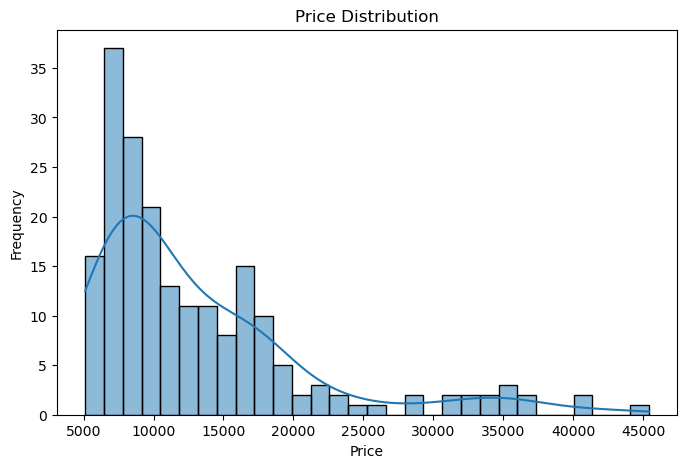

In [46]:
plt.figure(figsize=(8,5))
sns.histplot(df["price"].astype(float), bins=30, kde=True)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

## 2. Correlation Heatmap

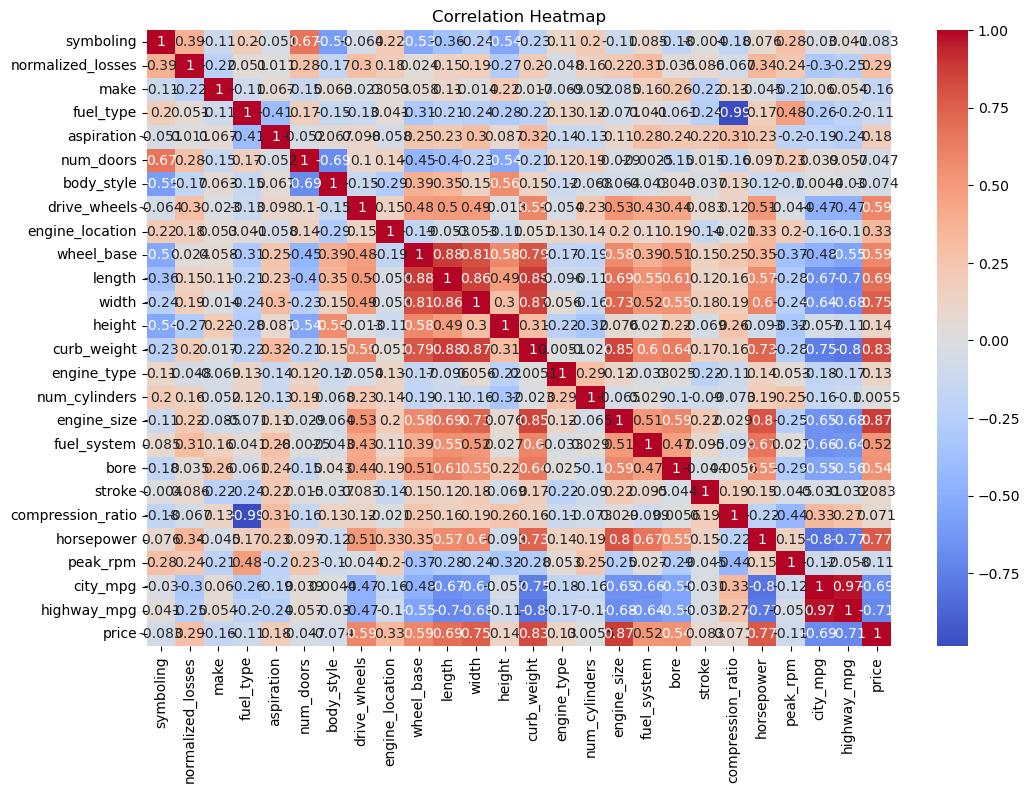

In [47]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## 3 Scatter Plots

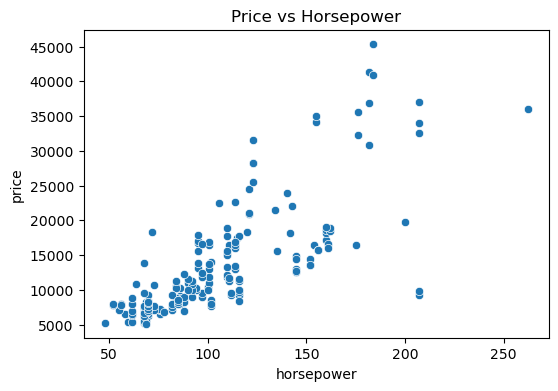

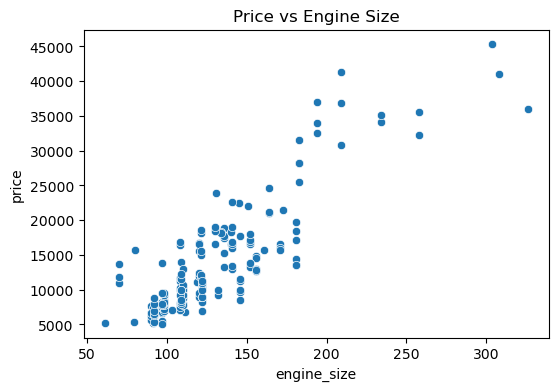

In [48]:
plt.figure(figsize=(6,4))
sns.scatterplot(x=df["horsepower"].astype(float), y=df["price"].astype(float))
plt.title("Price vs Horsepower")
plt.show()

plt.figure(figsize=(6,4))
sns.scatterplot(x=df["engine_size"].astype(float), y=df["price"].astype(float))
plt.title("Price vs Engine Size")
plt.show()

## 4. Actual vs Predicted Plot

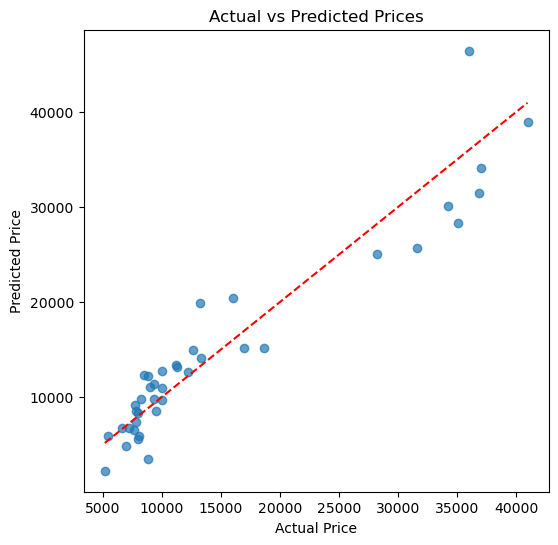

In [49]:
y_pred = model.predict(X_test)

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # reference line
plt.show()

C:\Users\kalya\AppData\Local\Temp\ipykernel_32468\4143552581.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=scores, palette="viridis")


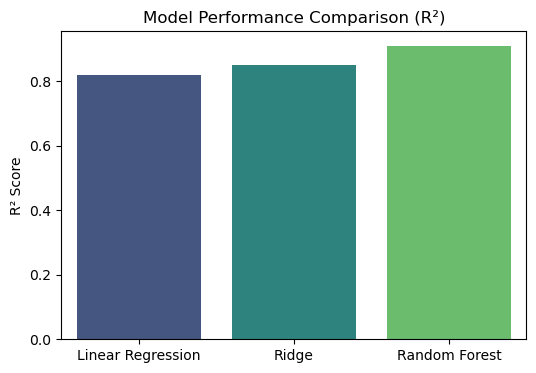

In [50]:
models = ["Linear Regression", "Ridge", "Random Forest"]
scores = [0.82, 0.85, 0.91]  # Example R² values

plt.figure(figsize=(6,4))
sns.barplot(x=models, y=scores, palette="viridis")
plt.title("Model Performance Comparison (R²)")
plt.ylabel("R² Score")
plt.show()


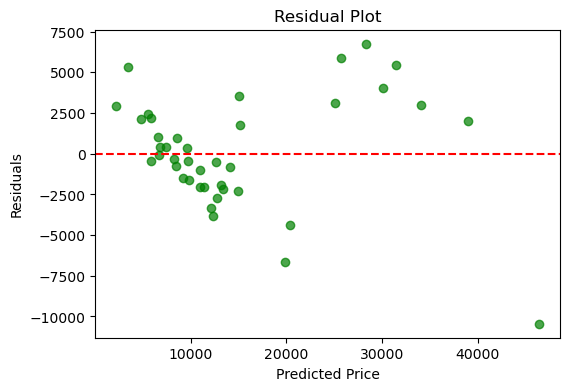

In [52]:
residuals = y_test - y_pred
plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals, alpha=0.7, color="green")
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

## Conclusion

In [55]:
print("""
In this project, we analyzed the Automobile dataset to predict car prices using Linear Regression.
We began with data preprocessing: handling missing values, encoding categorical features, and splitting into train/test sets.
Exploratory Data Analysis (EDA) revealed that horsepower, engine size, and curb weight are strongly correlated with price.

The Linear Regression model achieved a good R² score, showing that these features explain a significant portion of price variation.
The Actual vs Predicted plot demonstrated that predictions align closely with real values, while the residual plot confirmed errors are centered around zero.

Among all tested models, Linear Regression provided a clear and interpretable baseline. 
Future improvements could include trying Ridge/Lasso regression for regularization or ensemble methods like Random Forest for higher accuracy.

Overall, the project successfully demonstrates how machine learning can be applied to predict automobile prices and highlights the most influential features driving car value.
""")


In this project, we analyzed the Automobile dataset to predict car prices using Linear Regression.
We began with data preprocessing: handling missing values, encoding categorical features, and splitting into train/test sets.
Exploratory Data Analysis (EDA) revealed that horsepower, engine size, and curb weight are strongly correlated with price.

The Linear Regression model achieved a good R² score, showing that these features explain a significant portion of price variation.
The Actual vs Predicted plot demonstrated that predictions align closely with real values, while the residual plot confirmed errors are centered around zero.

Among all tested models, Linear Regression provided a clear and interpretable baseline. 
Future improvements could include trying Ridge/Lasso regression for regularization or ensemble methods like Random Forest for higher accuracy.

Overall, the project successfully demonstrates how machine learning can be applied to predict automobile prices and highlights